# 1. Analiza skupova podataka

Ovaj notebook odgovara na prvo pitanje iz mejla profesorice: **koji skupovi
podataka postoje, koje klase sadrže i da li odgovaraju problemu**.

Upoređuju se dva skupa:
- **BeeImage** — korišćen u prvom eksperimentu; pokazalo se da nije pogodan
- **VarroaDataset** — korišćen u glavnom eksperimentu

Ključno pitanje za svaki skup: *da li oznaka opisuje pčelu na slici, ili nešto drugo?*

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
pd.set_option("display.max_colwidth", 80)

## 1.1 BeeImage: koliko različitih snimaka stoji iza svake klase?

Ime fajla (`038_112.png`) počinje id-jem video snimka iz kog je pčela isečena.
Ako klasa dolazi iz malog broja snimaka, model može da nauči snimak umesto bolesti.

In [2]:
from src.dataset import load_split
bee = pd.concat([load_split(s, 3).assign(split=s) for s in ("train", "val", "test")], ignore_index=True)
bee["snimak"] = bee["file"].str.split("_").str[0]

pregled = bee.groupby("label").agg(slika=("file", "size"), snimaka=("snimak", "nunique"))
pregled

,slika,snimaka
label,,
drugi_problem,737,9
varoa_grinje,1051,5
zdrava,3384,31


Klasa **varoa** ima 1.051 sliku, ali iz samo **5 snimaka**. Uz to, nasumična podela
je svaki od tih snimaka stavila i u trening i u test:

In [3]:
v = bee[bee["label"] == "varoa_grinje"]
pd.crosstab(v["snimak"], v["split"])[["train", "val", "test"]]

split,train,val,test
snimak,,,
031,40,9,9
035,27,3,4
036,18,6,2
038,330,71,71
040,320,69,72


Test skup zato sadrži skoro iste frejmove kao trening — visoka tačnost na njemu ne
govori ništa o novim pčelama. Primeri slika po klasi (varoa ima prepoznatljivu
tirkiznu podlogu, a grinja se ne vidi):

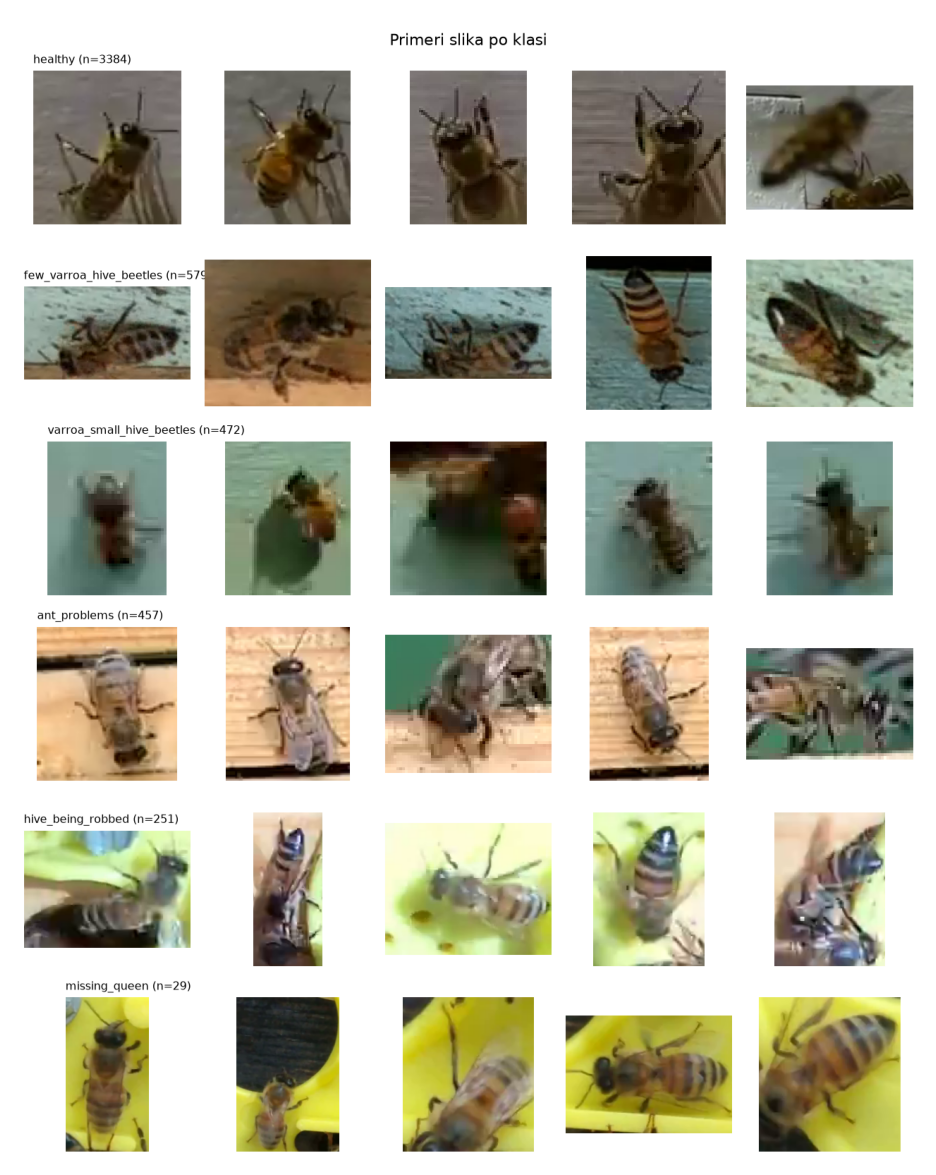

In [4]:
plt.figure(figsize=(12, 15)); plt.imshow(Image.open("report/figures/samples_per_class.png")); plt.axis("off");

## 1.2 VarroaDataset

Svaka pčela je označena posebno: 0 = zdrava, 1 = vidljiva grinja, 3 = nedokumentovano
(grinja delimično skrivena; autori je broje kao zaraženu). Za svaku grinju postoji
ručno nacrtan pravougaonik — koristi se samo za provere, ne za trening.

In [5]:
from src.varroa_dataset import parse_gt
df = parse_gt()
print("Ukupno slika:", len(df))
pd.crosstab(df["split"], df["label"], margins=True).loc[["train", "val", "test", "All"]]

Ukupno slika: 13509


label,varoa,zdrava,All
split,,,
train,2554,5671,8225
val,451,1425,1876
test,942,2466,3408
All,3947,9562,13509


In [6]:
pd.crosstab(df["split"], df["raw_label"]).loc[["train", "val", "test"]]

raw_label,0,1,3
split,,,
train,5671,1974,580
val,1425,373,78
test,2466,736,206


### Podela po snimku

Za razliku od BeeImage-a: **svaki snimak ima i zdrave i zaražene pčele**, i **nijedan
snimak nije u dva skupa**. Pozadina zato ne može da otkrije klasu, a test meri rad
na snimcima koje model nije video.

In [7]:
snimci = df.groupby("video").agg(split=("split", "first"), slika=("target", "size"),
                                  udeo_varoe=("target", "mean")).sort_values("split")
print("Snimak u više skupova:", int((df.groupby("video")["split"].nunique() > 1).sum()))
snimci.round(2)

Snimak u više skupova: 0


,split,slika,udeo_varoe
video,,,
2017-09-01_10-54-26,test,1278,0.48
2017-10-17_1-39-36,test,2130,0.15
2017-08-28_09-30-00-1_500_dirty_glass,train,1040,0.41
2017-08-28_16-31-55,train,5,1.00
2017-08-30_15-42-59,train,2020,0.17
2017-09-20_19-24-55,train,3839,0.38
2017-09-25_16-03-38-2,train,915,0.23
2017-10-17_16-41-10,train,406,0.30
2017-08-28_16-32-55_30_sec,val,52,0.60


### Veličina grinje na slici

In [8]:
boxes = [b for bs in df["boxes"] for b in bs]
w = np.array([b[2] - b[0] for b in boxes]); h = np.array([b[3] - b[1] for b in boxes])
print(f"Grinja: širina medijana {np.median(w):.0f} px, visina {np.median(h):.0f} px (slika je 160×280)")
print("Broj grinja po zaraženoj pčeli:", df[df.n_mites > 0].n_mites.value_counts().sort_index().to_dict())

Grinja: širina medijana 32 px, visina 31 px (slika je 160×280)
Broj grinja po zaraženoj pčeli: {1: 3332, 2: 549, 3: 66}


### Primeri (crveni pravougaonik nacrtan iz `gt.csv`; na samim slikama ga nema)

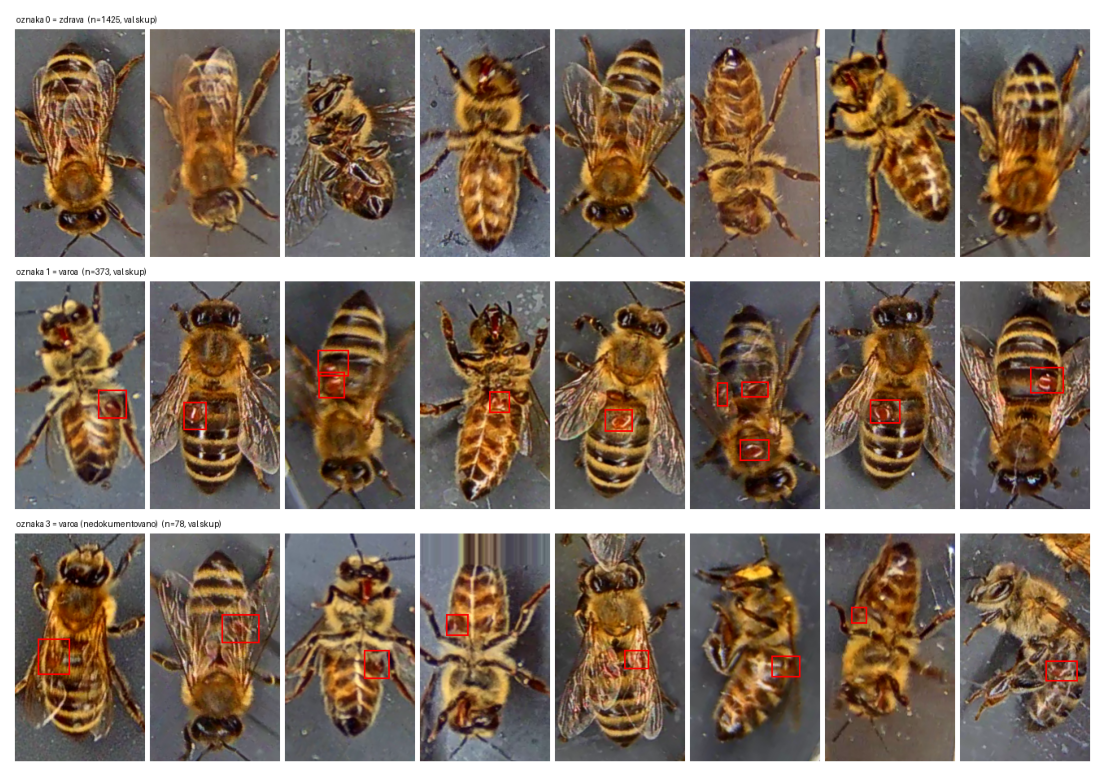

In [9]:
plt.figure(figsize=(14, 10)); plt.imshow(Image.open("report/figures/varroa_dataset_samples.png")); plt.axis("off");

## 1.3 Zaključak

| | BeeImage | VarroaDataset |
|---|---|---|
| Oznaka | po snimku | po pčeli, vidljiva grinja |
| Pozadina po klasama | različita | ista |
| Snimaka po klasi varoe | 5 | svih 13 sadrži obe klase |
| Podela | nasumična (curenje) | po snimku |

VarroaDataset ispunjava sve uslove i koristi se u glavnom eksperimentu.